# A fibre link: attenuation, receivers, eye diagrams and the bit error rate

The last notebook of the fibre series puts the pieces together into the
simplest digital link: a laser switched on and off by the bits
(non-return-to-zero on-off keying, NRZ), a span of fibre, and a photodiode
that decides at the centre of each bit whether it was a one or a zero. Two
things limit how far and how fast it works: the fibre loses light, so the
receiver must find the bits in noise, and the fibre spreads the bits into
each other (notebooks 117 (dispersion in fibres) and 118 (pulse broadening)). This notebook stays with the basics:

1. the loss of silica fibre and the three telecom windows, power in dBm,
2. the transmitter: bit patterns, extinction ratio, rise time, and a
   directly modulated laser from its rate equations, with its chirp,
   overshoot and intensity noise,
3. the receiver: shot and thermal noise, the Q factor and the bit error
   rate, PIN against APD receivers,
4. a simulated link with noise, checked against the formulas,
5. dispersion in the eye diagram, external modulator against directly
   modulated laser, and a real Mach–Zehnder modulator with its chirp,
   extinction and drive swing,
6. power and rise-time budgets of two example links,
7. a short look at what lies beyond (amplifiers, WDM, coherent).

Functions are in `pyoptics.fibrecomm` (signals, receiver, budgets),
`pyoptics.fibres` (attenuation, dispersion), `pyoptics.electrooptics`
(the modulator) and `pyoptics.lasers` (the laser diode). Practical units: time in ps,
length in km, power in mW or dBm, currents in mA (µA in the plots), bit
rates in Gb/s.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import electrooptics as eo, fibres, fibrecomm as fc, lasers, sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(120)

H_PLANCK = 6.62607015E-34
C_LIGHT = 2.99792458E8
smf = fibres.smf28()
D1550 = float(fibres.dispersion(smf, 1.55))
beta2 = fibres.beta2_from_D(D1550, 1550)
D1310 = float(fibres.dispersion(smf, 1.31))
print("SMF model: D = {:.2f} ps/(nm km) at 1550 nm (beta2 = {:.1f} ps²/km), {:.2f} at 1310 nm".format(
    D1550, beta2, D1310))

SMF model: D = 17.63 ps/(nm km) at 1550 nm (beta2 = -22.5 ps²/km), 0.80 at 1310 nm


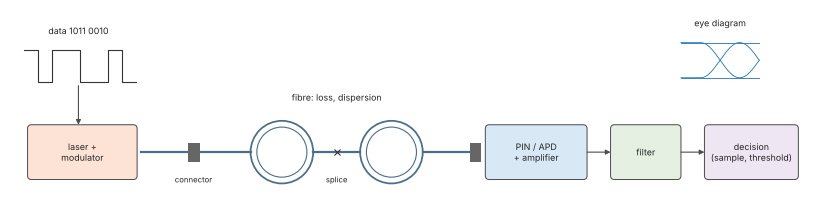

In [2]:
fig, ax = plt.subplots(figsize=(13, 3.6))
sketch.fibre_link(ax)
plt.show()

## 1. Loss and the telecom windows

Light in silica is lost by **Rayleigh scattering** on frozen-in density and
composition fluctuations, which falls as $\lambda^{-4}$, by the tail of
the **infrared** absorption of the Si–O bonds, which rises steeply above
1.6 µm, by the much weaker tail of the **ultraviolet** electronic
absorption (below 0.01 dB/km above 800 nm, not shown), and by the overtones of **OH** impurities, above all at
1383 nm. `fibres.attenuation_components()` models them with the usual
empirical forms (Rayleigh coefficient 0.9 dB µm⁴/km for a GeO₂-doped
single-mode core). Older fibres have an OH peak of 1 dB/km or more; "zero
water peak" fibres (ITU-T G.652.D) have almost none.

Losses add up in decibels, and powers are given in dBm, decibels relative
to 1 mW: 0 dBm = 1 mW, −30 dBm = 1 µW. A link with 0 dBm launched and
20 dB of loss delivers −20 dBm = 10 µW.

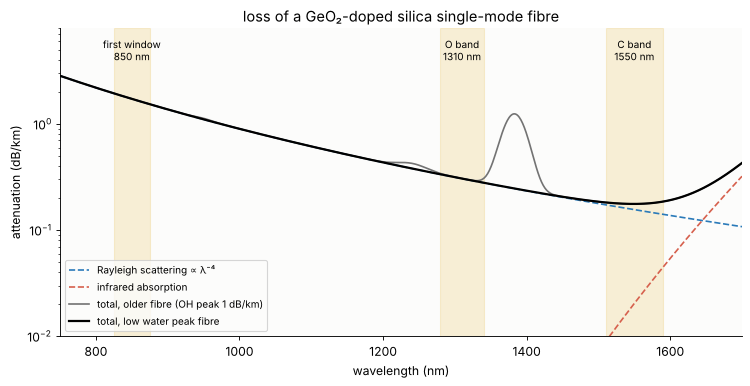

minimum: 0.176 dB/km at 1549 nm
     850 nm: 1.726 dB/km (older fibre 1.726)
    1310 nm: 0.306 dB/km (older fibre 0.306)
    1383 nm: 0.247 dB/km (older fibre 1.247)
    1550 nm: 0.176 dB/km (older fibre 0.176)
power after 100 km at 1550 nm with 1 mW launched: -17.6 dBm = 17.2 µW


In [3]:
wl = np.linspace(0.75, 1.70, 800)
comp = fibres.attenuation_components(wl)
old = fibres.attenuation(wl, oh_peak=1.0)

fig, ax = plt.subplots(figsize=(11, 5))
ax.semilogy(wl*1E3, comp["rayleigh"], color=BLUE, ls="--", label="Rayleigh scattering ∝ λ⁻⁴")
ax.semilogy(wl*1E3, comp["ir"], color=RED, ls="--", label="infrared absorption")
ax.semilogy(wl*1E3, old, color=GREY, lw=1.5, label="total, older fibre (OH peak 1 dB/km)")
ax.semilogy(wl*1E3, comp["total"], color="k", lw=2, label="total, low water peak fibre")
for c, w, name in ((850, 50, "first window\n850 nm"), (1310, 60, "O band\n1310 nm"),
                   (1550, 80, "C band\n1550 nm")):
    ax.axvspan(c - w/2, c + w/2, color=ORANGE, alpha=0.15)
    ax.text(c, 4, name, ha="center", fontsize=9)
ax.set_ylim(0.01, 8); ax.set_xlim(750, 1700)
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("attenuation (dB/km)")
ax.set_title("loss of a GeO₂-doped silica single-mode fibre")
ax.legend(fontsize=9, loc="lower left")
plt.show()

i_min = np.argmin(comp["total"])
print("minimum: {:.3f} dB/km at {:.0f} nm".format(comp["total"][i_min], wl[i_min]*1E3))
for w in (0.85, 1.31, 1.383, 1.55):
    print("  {:6.0f} nm: {:.3f} dB/km (older fibre {:.3f})".format(
        w*1E3, float(fibres.attenuation(w)), float(fibres.attenuation(w, oh_peak=1.0))))
print("power after 100 km at 1550 nm with 1 mW launched: {:.1f} dBm = {:.1f} µW".format(
    0 - 100*float(fibres.attenuation(1.55)), fc.mw(-100*float(fibres.attenuation(1.55)))*1E3))

The model gives 0.18 dB/km at 1550 nm, the data sheet value of standard
fibre (installed cables are closer to 0.2–0.25 dB/km with splices and
bends), 0.31 dB/km at 1310 nm and 1.7 dB/km at 850 nm. The minimum near
1550 nm, where Rayleigh scattering meets the infrared absorption, is why
long links use the C band; 100 km cost 18 dB, a factor of 60. The 850 nm
window survives for short multimode links because cheap lasers (VCSELs)
and silicon detectors work there, and 1310 nm because the standard fibre
has no dispersion there (notebook 117, dispersion in fibres).

## 2. The transmitter

The test signal is a **pseudo-random bit sequence**: PRBS7 from a seven
bit shift register repeats after 127 bits and contains every pattern of
seven bits except all zeros, so it exercises the link like random data.
The transmitter does not switch instantly: `fc.nrz()` gives the power a
10–90 % **rise time** (by default 30 % of a bit), and a real laser is never
quite dark for a zero; the **extinction ratio** $r_{ex} = P_1/P_0$ is
typically 7 to 10 dB. An **external modulator** (a Mach–Zehnder
interferometer in LiNbO₃ or InP after a continuous wave laser) switches the
power without chirp. A **directly modulated laser** (DML), whose current is
switched, follows its rate equations (notebook 144, laser diodes): the
power overshoots and rings at the relaxation oscillation, and the frequency
follows the carrier density,

$$
\delta\nu(t) = \frac{\alpha_H}{4\pi}\left(\frac{d\ln P}{dt} + \kappa P\right),
$$

with the linewidth enhancement factor $\alpha_H$ = 3 to 6: a transient chirp
on the edges and an adiabatic chirp $\kappa P$ from gain compression. The
transmitter here is the 1.55 µm DFB laser of `lasers.DiodeLaser()`
(threshold 15 mA), biased at 25 mA and switched to 65 mA, scaled to 1 mW
in the ones; `fc.nrz()` with `alpha_h` is the simpler model with the
transient chirp only.

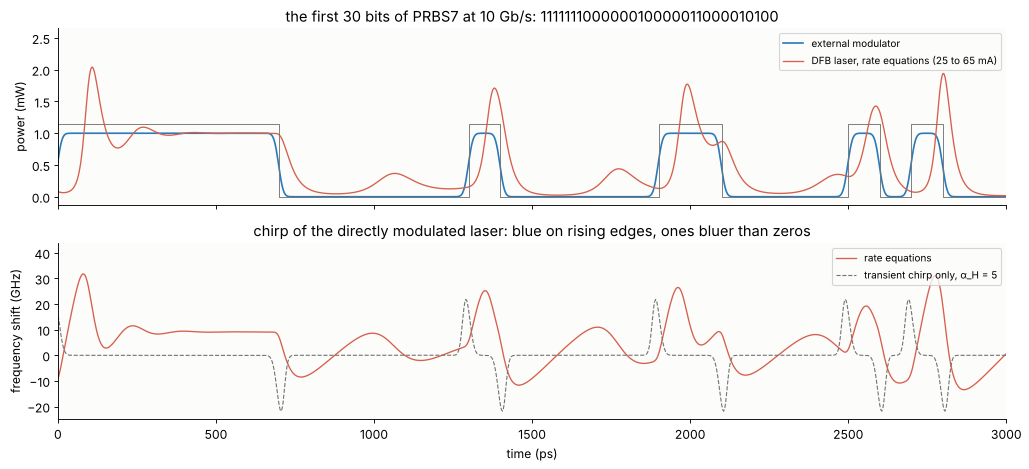

PRBS7: 127 bits, 64 ones
DFB laser: extinction 7.1 dB, chirp +41 / -15 GHz (transient only: +22 / -22 GHz)
modulation bandwidth at the bias: 4.4 GHz (relaxation oscillation 2.9 GHz)


In [4]:
B = 10.0                     # Gb/s
T_bit = 1E3/B                # ps
bits = fc.prbs(7)
t, A_em = fc.nrz(bits, B, samples_per_bit=32, p1=1.0)
dfb = lasers.DiodeLaser()    # 1.55 µm InGaAsP DFB laser (Agrawal, table 3.1)
i_bias, i_mod = 25E-3, 40E-3
P1_dfb, P0_dfb = dfb.li_curve([i_bias + i_mod, i_bias])[0]
_, A_dml, I_drive = dfb.nrz(bits, B, i_bias, i_mod, samples_per_bit=32)
A_dml = A_dml/np.sqrt(P1_dfb*1E3)                    # ones at 1 mW
_, A_tr = fc.nrz(bits, B, samples_per_bit=32, p1=1.0, extinction=P1_dfb/P0_dfb, alpha_h=dfb.alpha)
dt = t[1] - t[0]
# instantaneous frequency shift (GHz): -d phi/dt/(2 pi) for exp(-i omega t)
nu_dml = -np.gradient(np.unwrap(np.angle(A_dml)), dt)/(2*np.pi)*1E3
nu_tr = -np.gradient(np.unwrap(np.angle(A_tr)), dt)/(2*np.pi)*1E3

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(t, np.abs(A_em)**2, color=BLUE, lw=1.5, label="external modulator")
axes[0].plot(t, np.abs(A_dml)**2, color=RED, lw=1.2,
             label=f"DFB laser, rate equations ({i_bias*1E3:.0f} to {(i_bias + i_mod)*1E3:.0f} mA)")
axes[0].step(np.arange(len(bits))*T_bit, bits*1.15, where="post", color=GREY, lw=0.8)
axes[0].set_ylabel("power (mW)"); axes[0].legend(fontsize=9, loc="upper right")
axes[0].set_title("the first 30 bits of PRBS7 at 10 Gb/s: " + "".join(map(str, bits[:30])))
axes[1].plot(t, nu_dml, color=RED, lw=1.2, label="rate equations")
axes[1].plot(t, nu_tr, color=GREY, lw=1.0, ls="--", label=f"transient chirp only, α_H = {dfb.alpha:g}")
axes[1].set_ylabel("frequency shift (GHz)"); axes[1].set_xlabel("time (ps)")
axes[1].set_title("chirp of the directly modulated laser: blue on rising edges, ones bluer than zeros")
axes[1].legend(fontsize=9, loc="upper right")
axes[1].set_xlim(0, 30*T_bit)
plt.tight_layout()
plt.show()
print("PRBS7: {} bits, {} ones".format(len(bits), bits.sum()))
print("DFB laser: extinction {:.1f} dB, chirp {:+.0f} / {:+.0f} GHz (transient only: {:+.0f} / {:+.0f} GHz)".format(
    10*np.log10(P1_dfb/P0_dfb), nu_dml.max(), nu_dml.min(), nu_tr.max(), nu_tr.min()))
print("modulation bandwidth at the bias: {:.1f} GHz (relaxation oscillation {:.1f} GHz)".format(
    dfb.bandwidth_3db(i_bias)/1E9, dfb.relaxation(i_bias)[0]/1E9))

The laser swings from −15 to +41 GHz, far more than the 10 GHz bandwidth
of the modulation itself, and the transient model with the same $\alpha_H$
misses both the offset of 6 GHz between ones and zeros and the ringing.
At this bias the laser's modulation bandwidth, 4.4 GHz, is below the 7 GHz
that 10 Gb/s needs, so the power overshoots on rising edges and the ones
are not flat. At 1550 nm the dispersion spreads the chirped edges further
(section 5).

## 3. The receiver: noise, Q factor and bit error rate

A photodiode turns the power $P$ into the current $I = RP$, with the
responsivity $R = \eta e\lambda/(hc)$, 0.9 A/W for an InGaAs PIN diode at
1550 nm ($\eta$ = 72 %). Two kinds of noise sit on this current in the
electrical bandwidth $\Delta f$ (about 0.7 times the bit rate for NRZ):

- **shot noise** of the photoelectrons, $\sigma_s^2 = 2eI\Delta f$,
  larger for ones than for zeros,
- **thermal noise** of the load resistor and amplifier,
  $\sigma_T^2 = 4k_BTF_n\Delta f/R_L$, the same for both.

The decision circuit compares the current at the centre of each bit with a
threshold. If the currents of ones and zeros scatter as Gaussians with
means $I_1, I_0$ and widths $\sigma_1, \sigma_0$, the best threshold gives

$$
\mathrm{BER} = \tfrac{1}{2}\operatorname{erfc}\!\left(\frac{Q}{\sqrt 2}\right),
\qquad Q = \frac{I_1 - I_0}{\sigma_1 + \sigma_0}.
$$

$Q$ = 6 gives a bit error rate of $10^{-9}$, $Q$ = 7 about $10^{-12}$.
The **sensitivity** is the average received power needed for a given $Q$.
An **avalanche photodiode** (APD) multiplies the photocurrent by a gain
$M$, which lifts the signal above the thermal noise, but it multiplies the
shot noise by $M^2F(M)$ with the excess noise factor
$F = k_AM + (1 - k_A)(2 - 1/M)$. Its sensitivity therefore has an optimum
gain.

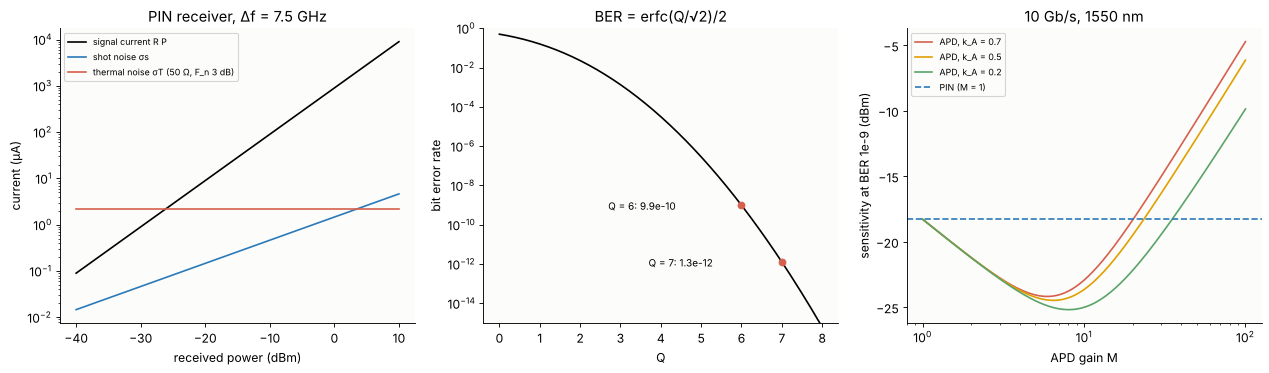

thermal noise 2.22 µA; shot noise equals it at 3.6 dBm
sensitivity at BER 1e-9 (Q = 6), 10 Gb/s:
  PIN:                 -18.3 dBm =  14.8 µW,  11583 photons per bit
  APD (k_A = 0.7, M = 5.9):  -24.2 dBm =   3.8 µW,   2986 photons per bit
  quantum limit (no thermal noise, BER 1e-9): 10 photons per bit = -48.9 dBm


In [5]:
R = 0.9                      # A/W
f3 = 0.7*B                   # GHz, 3 dB bandwidth of the receiver filter
nbw = fc.noise_bandwidth(f3)  # 1.064 f3 for the Gaussian filter of fc.detect()
k_A = 0.7                    # InP multiplication region

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
Pin = np.logspace(-4, 1, 300)          # mW
s_sh, s_th = fc.receiver_noise(Pin, nbw, R)
axes[0].loglog(fc.dbm(Pin), R*Pin*1E3, color="k", label="signal current R P")
axes[0].loglog(fc.dbm(Pin), s_sh*1E3, color=BLUE, label="shot noise σs")
axes[0].loglog(fc.dbm(Pin), s_th*1E3, color=RED, label="thermal noise σT (50 Ω, F_n 3 dB)")
axes[0].set_xscale("linear")
axes[0].set_xlabel("received power (dBm)"); axes[0].set_ylabel("current (µA)")
axes[0].set_title(f"PIN receiver, Δf = {nbw:.1f} GHz"); axes[0].legend(fontsize=8)

Q = np.linspace(0, 8, 200)
axes[1].semilogy(Q, fc.ber(Q), color="k")
for q in (6, 7):
    axes[1].plot(q, fc.ber(q), "o", color=RED)
    axes[1].annotate(f"Q = {q}: {fc.ber(q):.1e}", (q, fc.ber(q)), textcoords="offset points",
                     xytext=(-120, -4), fontsize=9)
axes[1].set_ylim(1E-15, 1); axes[1].set_xlabel("Q"); axes[1].set_ylabel("bit error rate")
axes[1].set_title("BER = erfc(Q/√2)/2")

M = np.logspace(0, 2, 200)
for k, c in ((0.7, RED), (0.5, ORANGE), (0.2, GREEN)):
    axes[2].semilogx(M, fc.dbm(fc.sensitivity(6, nbw, R, M, k)), color=c, label=f"APD, k_A = {k}")
axes[2].axhline(fc.dbm(fc.sensitivity(6, nbw, R)), color=BLUE, ls="--", label="PIN (M = 1)")
axes[2].set_xlabel("APD gain M"); axes[2].set_ylabel("sensitivity at BER 1e-9 (dBm)")
axes[2].set_title("10 Gb/s, 1550 nm"); axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

P_pin = float(fc.sensitivity(6, nbw, R))
M_opt, P_apd = fc.optimum_apd_gain(6, nbw, R, k_A)
E_photon = H_PLANCK*C_LIGHT/1.55E-6
print("thermal noise {:.2f} µA; shot noise equals it at {:.1f} dBm".format(
    float(s_th[0])*1E3, fc.dbm(Pin[np.argmin(abs(s_sh - s_th))])))
print("sensitivity at BER 1e-9 (Q = 6), 10 Gb/s:")
print("  PIN:                {:6.1f} dBm = {:5.1f} µW, {:6.0f} photons per bit".format(
    fc.dbm(P_pin), P_pin*1E3, P_pin*1E-3/(E_photon*B*1E9)))
print("  APD (k_A = 0.7, M = {:.1f}): {:6.1f} dBm = {:5.1f} µW, {:6.0f} photons per bit".format(
    M_opt, fc.dbm(P_apd), P_apd*1E3, P_apd*1E-3/(E_photon*B*1E9)))
print("  quantum limit (no thermal noise, BER 1e-9): 10 photons per bit = {:.1f} dBm".format(
    fc.dbm(10*E_photon*B*1E9*1E3)))

Below about 0 dBm the PIN receiver is limited by **thermal noise**: the
signal current falls with the power, the noise stays, and the sensitivity
at 10 Gb/s is about −18 dBm, some 12 000 photons per bit. An APD at its
optimum gain of about 6 gains 6 dB (3000 photons per bit); a better (lower
$k_A$) multiplication region a little more. Real receivers with low noise
transimpedance amplifiers do 1 to 2 dB better than this 50 Ω model, about
−19 to −20 dBm (PIN) and −26 dBm (APD) at 10 Gb/s, still a few hundred
times above the quantum limit of 10 photons per bit. Thermal noise grows as $\sqrt{\Delta f}$, so the
sensitivity of a thermal noise limited receiver scales as $\sqrt B$: each
doubling of the bit rate costs 1.5 dB.

### Intensity noise of the laser

The laser adds noise of its own. Its relative intensity noise (notebook
144, laser diodes) puts a current noise $\sigma_{RIN} = RP\sqrt{\mathrm{RIN}\,\Delta f}$
on each level (`fc.rin_noise()`), which grows with the received power like
the signal. It does not change the sensitivity of a thermal noise limited
receiver much, but it sets a ceiling on $Q$ however strong the signal,
$Q_{max} = (P_1 - P_0)/((P_1\sqrt{\mathrm{RIN}_1} + P_0\sqrt{\mathrm{RIN}_0})\sqrt{\Delta f})$.
The RIN of each level is taken from the rate equations at its current,
averaged over the receiver band. A laser biased close to threshold for a
high extinction ratio has the zeros where the RIN is highest.


noiseless, extinction 7 dB    : extinction  7.1 dB, Q = 6 at  -16.6 dBm, Q ceiling    inf
DFB biased at 25 mA (7 dB)    : extinction  7.1 dB, Q = 6 at  -16.5 dBm, Q ceiling   49.0
DFB biased at 18 mA           : extinction 12.1 dB, Q = 6 at  -17.7 dBm, Q ceiling   51.4


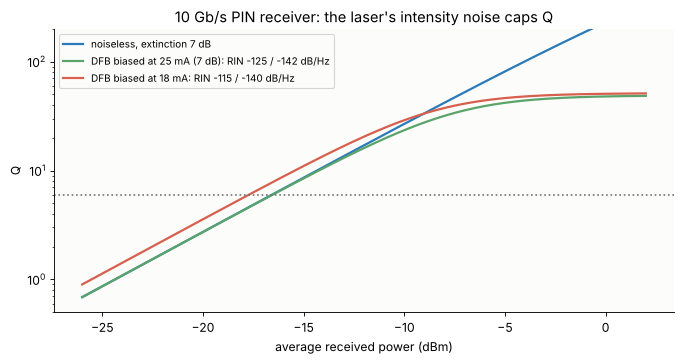

In [6]:
f_band = np.linspace(0.01E9, nbw*1E9, 400)


def rin_db(i):
    """RIN (dB/Hz) of the DFB laser at the current i, averaged over the receiver band"""
    return 10*np.log10(np.mean(dfb.rin(f_band, i)))


P_avg_dbm = np.linspace(-26, 2, 300)
lasers_rin = [("noiseless, extinction 7 dB", 25E-3, False, BLUE),
              ("DFB biased at 25 mA (7 dB)", 25E-3, True, GREEN),
              ("DFB biased at 18 mA", 18E-3, True, RED)]
fig, ax = plt.subplots(figsize=(10, 4.6))
for name, ib, noisy, c in lasers_rin:
    P1x, P0x = dfb.li_curve([ib + i_mod, ib])[0]
    r_ex = P1x/P0x
    P_avg = fc.mw(P_avg_dbm)
    p1, p0 = 2*P_avg*r_ex/(r_ex + 1), 2*P_avg/(r_ex + 1)
    s1 = np.hypot(*fc.receiver_noise(p1, nbw, R))
    s0 = np.hypot(*fc.receiver_noise(p0, nbw, R))
    if noisy:
        rin1, rin0 = rin_db(ib + i_mod), rin_db(ib)
        s1 = np.hypot(s1, fc.rin_noise(p1, nbw, rin1, R))
        s0 = np.hypot(s0, fc.rin_noise(p0, nbw, rin0, R))
        q_max = (1 - 1/r_ex)/(np.sqrt(10**(rin1/10)*nbw*1E9) + np.sqrt(10**(rin0/10)*nbw*1E9)/r_ex)
        label = f"{name}: RIN {rin0:.0f} / {rin1:.0f} dB/Hz"
    else:
        q_max = np.inf
        label = name
    Q_x = fc.q_factor(R*p1, R*p0, s1, s0)
    ax.semilogy(P_avg_dbm, Q_x, color=c, lw=2, label=label)
    sens = np.interp(6, Q_x, P_avg_dbm) if Q_x.max() > 6 else np.nan
    print("{:30s}: extinction {:4.1f} dB, Q = 6 at {:6.1f} dBm, Q ceiling {:6.1f}".format(
        name, 10*np.log10(r_ex), sens, q_max))
ax.axhline(6, color=GREY, ls=":")
ax.set_xlabel("average received power (dBm)"); ax.set_ylabel("Q")
ax.set_title("10 Gb/s PIN receiver: the laser's intensity noise caps Q")
ax.legend(fontsize=9); ax.set_ylim(0.5, 200)
plt.show()

The DFB laser is quiet enough for this link. Biased at 25 mA its zeros
have a RIN of −125 dB/Hz over the receiver band and its ones −142 dB/Hz;
the ceiling is $Q \approx$ 49, and the sensitivity moves by 0.1 dB.
Biased at 18 mA, just above threshold, the zeros sit at the relaxation
peak of the noise (−115 dB/Hz), but they are also dim, and the ceiling
stays near 50; the higher extinction ratio (12 dB) even gains 1 dB of
sensitivity. The finite extinction itself costs more: 1.4 dB against the
ideal switch (−18 dBm). RIN matters where the signal is strong and the
format sensitive: analog links (cable TV over fibre needs below
−150 dB/Hz), multilevel formats, and amplified links where the receiver
sees milliwatts.

## 4. A simulated link with noise

`fc.detect()` turns the field envelope into a current behind a Gaussian
receiver filter and adds Gaussian shot and thermal noise. Sampling 64
periods of PRBS7 (8128 bits) at the bit centres gives the histograms of
ones and zeros, their means and widths, and so a measured $Q$. Here the
received power is swept around the PIN sensitivity, back to back (no
fibre).

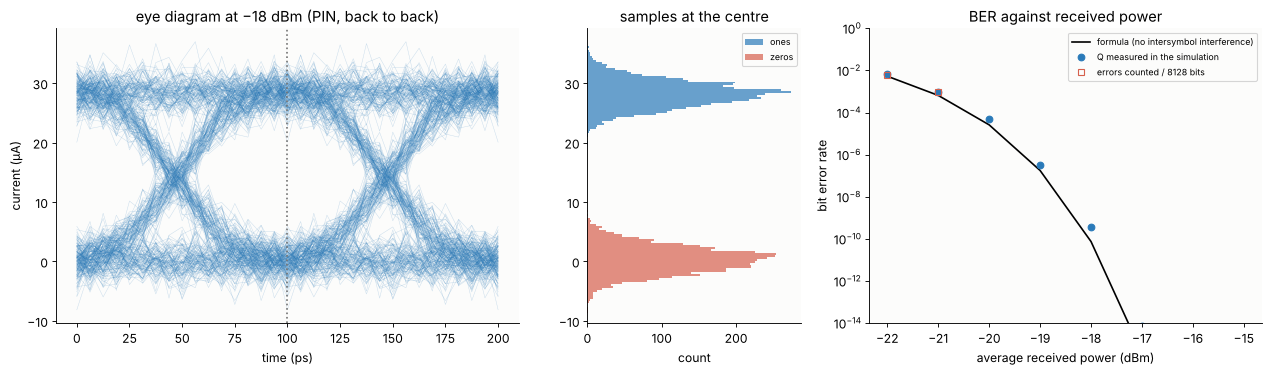

 -22.0 dBm: Q measured  2.48, formula  2.55, BER 6.6e-03, errors   49
 -21.0 dBm: Q measured  3.12, formula  3.22, BER 9.0e-04, errors    8
 -20.0 dBm: Q measured  3.89, formula  4.05, BER 4.9e-05, errors    0
 -19.0 dBm: Q measured  4.97, formula  5.09, BER 3.3e-07, errors    0
 -18.0 dBm: Q measured  6.16, formula  6.40, BER 3.7e-10, errors    0
 -17.0 dBm: Q measured  7.69, formula  8.06, BER 7.1e-15, errors    0
 -16.0 dBm: Q measured  9.73, formula 10.13, BER 1.2e-22, errors    0
 -15.0 dBm: Q measured 11.92, formula 12.74, BER 4.4e-33, errors    0
noise-free eye opening behind the receiver filter: 95.0 % of R P1


In [7]:
spb = 16
bits_long = np.tile(bits, 64)
centres = np.arange(len(bits_long))*spb + spb//2
P_rx_dbm = np.arange(-22.0, -14.9, 1.0)
Q_meas, Q_theory, errors = [], [], []
for p_dbm in P_rx_dbm:
    p_avg = fc.mw(p_dbm)
    t_l, A_l = fc.nrz(bits_long, B, samples_per_bit=spb, p1=2*p_avg)
    I = fc.detect(t_l, A_l, f3, R, rng=rng)
    v = I[centres]
    ones, zeros = v[bits_long == 1], v[bits_long == 0]
    Q_meas.append(fc.q_factor(ones.mean(), zeros.mean(), ones.std(), zeros.std()))
    sh1, th = fc.receiver_noise(2*p_avg, nbw, R)
    Q_theory.append(fc.q_factor(R*2*p_avg, 0, np.hypot(sh1, th), th))
    thr = zeros.mean() + (ones.mean() - zeros.mean())*th/(np.hypot(sh1, th) + th)
    errors.append(np.sum((v > thr) != (bits_long == 1)))
Q_meas, Q_theory = np.array(Q_meas), np.array(Q_theory)

p_show = fc.mw(-18.0)
t_l, A_l = fc.nrz(bits_long, B, samples_per_bit=spb, p1=2*p_show)
I = fc.detect(t_l, A_l, f3, R, rng=rng)
tau, traces = fc.eye_diagram(t_l, I, B, offset=T_bit/2)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.3, 0.6, 1.1]})
for tr in traces[:400]:
    axes[0].plot(tau, tr*1E3, color=BLUE, lw=0.4, alpha=0.25)
axes[0].axvline(T_bit, color=GREY, ls=":")
axes[0].set_xlabel("time (ps)"); axes[0].set_ylabel("current (µA)")
axes[0].set_title("eye diagram at −18 dBm (PIN, back to back)")
v = I[centres]
axes[1].hist(v[bits_long == 1]*1E3, bins=50, orientation="horizontal", color=BLUE, alpha=0.7, label="ones")
axes[1].hist(v[bits_long == 0]*1E3, bins=50, orientation="horizontal", color=RED, alpha=0.7, label="zeros")
axes[1].set_ylim(axes[0].get_ylim()); axes[1].set_xlabel("count"); axes[1].legend(fontsize=8)
axes[1].set_title("samples at the centre")
axes[2].semilogy(P_rx_dbm, fc.ber(Q_theory), color="k", label="formula (no intersymbol interference)")
axes[2].semilogy(P_rx_dbm, fc.ber(Q_meas), "o", color=BLUE, label="Q measured in the simulation")
cnt = np.array(errors)
ok = cnt > 0
axes[2].semilogy(P_rx_dbm[ok], cnt[ok]/len(bits_long), "s", mfc="none", color=RED,
                 label="errors counted / 8128 bits")
axes[2].set_ylim(1E-14, 1); axes[2].set_xlabel("average received power (dBm)")
axes[2].set_ylabel("bit error rate"); axes[2].legend(fontsize=8)
axes[2].set_title("BER against received power")
plt.tight_layout()
plt.show()
for p, qm, qt, e in zip(P_rx_dbm, Q_meas, Q_theory, errors):
    print("{:6.1f} dBm: Q measured {:5.2f}, formula {:5.2f}, BER {:.1e}, errors {:4d}".format(
        p, qm, qt, fc.ber(qm), e))
eye0 = fc.eye_opening(fc.eye_diagram(t, fc.detect(t, A_em, f3, R, noise=False), B,
                                     offset=T_bit/2)[1], np.roll(bits, -1))
print("noise-free eye opening behind the receiver filter: {:.1f} % of R P1".format(eye0/R*100))

The simulation follows the formula to within about 0.2 dB: the receiver
filter (bandwidth 0.7 B) and the transmitter rise time close the eye to
95 % before any noise is added (intersymbol interference), and $Q$ shrinks
in proportion. The counted errors agree with
the BER from $Q$ where there are enough of them to count; at
$10^{-9}$ one would need billions of bits, which is why $Q$ (or the eye
opening) is measured instead. Each decibel of received power changes the
BER by orders of magnitude: the BER curve is very steep, and links are
designed with a few dB of **margin**.

## 5. Dispersion in the eye diagram

Notebook 118 (pulse broadening) followed single pulses; a link sees all bit patterns at once.
At 1550 nm the standard fibre has $D \approx 17$ ps/(nm km). An externally
modulated 10 Gb/s signal (spectral width about 0.1 nm) tolerates some
tens of km; a directly modulated laser, whose chirp widens the spectrum,
much less. At 1310 nm, near the zero of $D$, the same fibre is harmless.
The **eye opening penalty** $10\log_{10}(\text{opening}_0/\text{opening}_L)$
is the extra received power needed to restore the eye of a thermal noise
limited receiver. (Without noise; the sampling time is chosen for the
widest opening.)

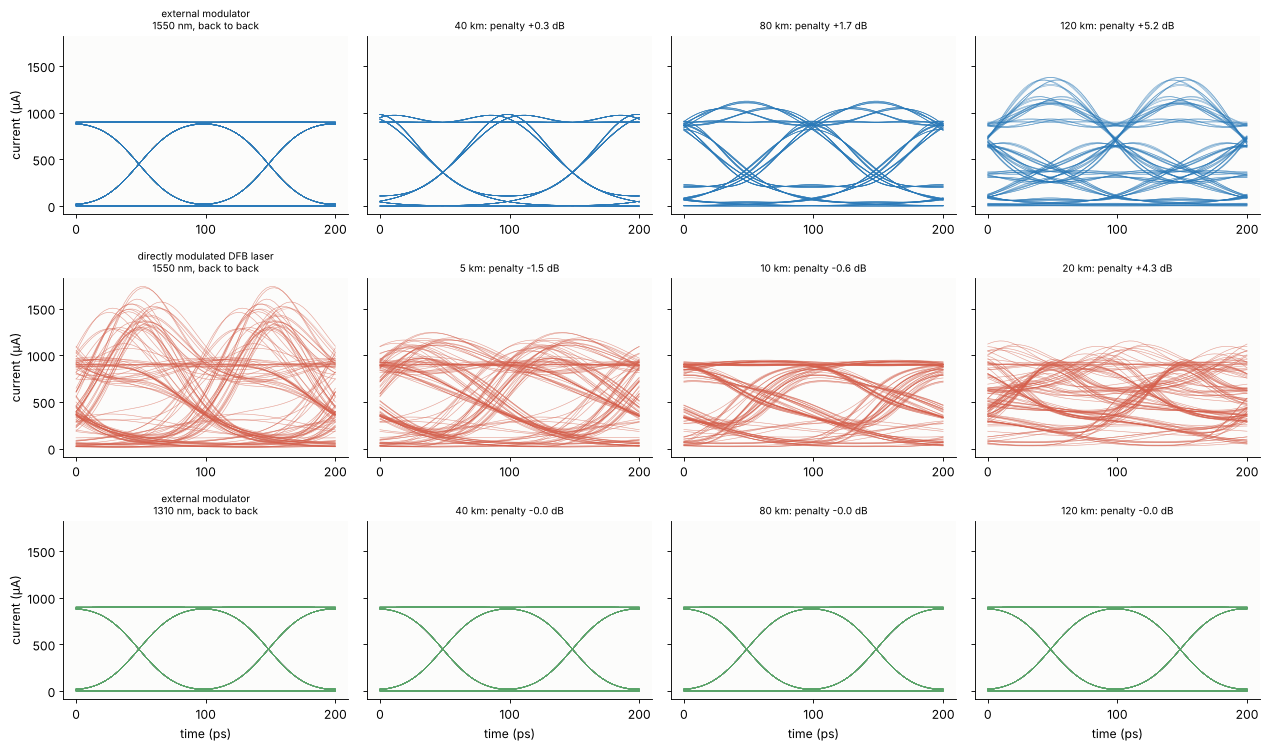

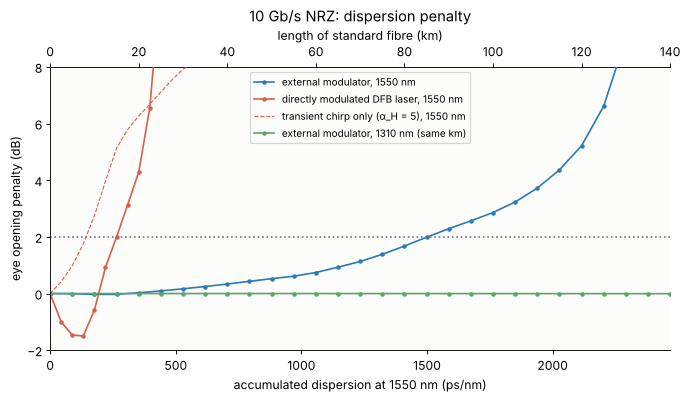

2 dB penalty: external modulator 85 km (1502 ps/nm), DML 15 km (265 ps/nm), transient chirp model 8 km
DML: back to back eye 0.35 of the external modulator's; penalty -1.5 dB at 5 km
1310 nm after 140 km: 0.01 dB


In [8]:
bits2 = np.tile(bits, 2)
t2, A_em2 = fc.nrz(bits2, B, samples_per_bit=32, p1=1.0)
_, A_dml2, _ = dfb.nrz(bits2, B, i_bias, i_mod, samples_per_bit=32)
A_dml2 = A_dml2/np.sqrt(P1_dfb*1E3)
_, A_tr2 = fc.nrz(bits2, B, samples_per_bit=32, p1=1.0, extinction=P1_dfb/P0_dfb, alpha_h=dfb.alpha)
ref_bits = np.roll(bits2, -1)
beta2_1310 = fibres.beta2_from_D(D1310, 1310)


def eye(A, L, b2):
    I = fc.detect(t2, fc.propagate(t2, A, L, b2), f3, R, noise=False)
    tau, tr = fc.eye_diagram(t2, I, B, offset=T_bit/2)
    openings = [fc.eye_opening(tr, ref_bits, sample=s) for s in range(16, 49)]
    return tau, tr, max(openings)


cases = [("external modulator, 1550 nm", A_em2, beta2, (0, 40, 80, 120), BLUE),
         ("directly modulated DFB laser, 1550 nm", A_dml2, beta2, (0, 5, 10, 20), RED),
         ("external modulator, 1310 nm", A_em2, beta2_1310, (0, 40, 80, 120), GREEN)]
fig, axes = plt.subplots(3, 4, figsize=(16, 9.5), sharey=True)
open0 = {}
for row, (name, A, b2, Ls, c) in zip(axes, cases):
    for ax, L in zip(row, Ls):
        tau, tr, op = eye(A, L, b2)
        if L == 0:
            open0[name] = op
        for x in tr:
            ax.plot(tau, x*1E3, color=c, lw=0.5, alpha=0.35)
        pen = 10*np.log10(open0[name]/op) if op > 0 else np.inf
        ax.set_title(f"{L} km: penalty {pen:+.1f} dB" if L else f"{name.split(',')[0]}\n{name.split(',')[1].strip()}, back to back",
                     fontsize=9)
        ax.set_xticks([0, 100, 200])
    row[0].set_ylabel("current (µA)")
for ax in axes[-1]:
    ax.set_xlabel("time (ps)")
plt.tight_layout()
plt.show()

Ls = np.arange(0, 141, 5)
pen_em = [10*np.log10(open0[cases[0][0]]/max(eye(A_em2, L, beta2)[2], 1E-9)) for L in Ls]
Ls_d = np.arange(0, 41, 2.5)
pen_dml = [10*np.log10(open0[cases[1][0]]/max(eye(A_dml2, L, beta2)[2], 1E-9)) for L in Ls_d]
open_tr = eye(A_tr2, 0, beta2)[2]
pen_tr = [10*np.log10(open_tr/max(eye(A_tr2, L, beta2)[2], 1E-9)) for L in Ls_d]
pen_1310 = [10*np.log10(open0[cases[2][0]]/max(eye(A_em2, L, beta2_1310)[2], 1E-9)) for L in Ls]

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(Ls*D1550, pen_em, "-o", ms=3, color=BLUE, label="external modulator, 1550 nm")
ax.plot(Ls_d*D1550, pen_dml, "-o", ms=3, color=RED, label="directly modulated DFB laser, 1550 nm")
ax.plot(Ls_d*D1550, pen_tr, "--", color=RED, lw=1, label=f"transient chirp only (α_H = {dfb.alpha:g}), 1550 nm")
ax.plot(Ls*D1550, pen_1310, "-o", ms=3, color=GREEN, label="external modulator, 1310 nm (same km)")
ax.axhline(2, color=GREY, ls=":")
ax.set_ylim(-2, 8); ax.set_xlim(0, 140*D1550)
ax.set_xlabel("accumulated dispersion at 1550 nm (ps/nm)")
sec = ax.secondary_xaxis("top", functions=(lambda x: x/D1550, lambda L: L*D1550))
sec.set_xlabel("length of standard fibre (km)")
ax.set_ylabel("eye opening penalty (dB)")
ax.set_title("10 Gb/s NRZ: dispersion penalty")
ax.legend(fontsize=9)
plt.show()


def reach(Ls, pen, limit=2.0):
    pen = np.asarray(pen)
    i = np.argmax(pen > limit)
    return np.interp(limit, pen[i - 1:i + 1], Ls[i - 1:i + 1])


L_em, L_dml, L_tr = reach(Ls, pen_em), reach(Ls_d, pen_dml), reach(Ls_d, pen_tr)
print("2 dB penalty: external modulator {:.0f} km ({:.0f} ps/nm), DML {:.0f} km ({:.0f} ps/nm), "
      "transient chirp model {:.0f} km".format(L_em, L_em*D1550, L_dml, L_dml*D1550, L_tr))
print("DML: back to back eye {:.2f} of the external modulator's; penalty {:+.1f} dB at 5 km".format(
    open0[cases[1][0]]/open0[cases[0][0]], float(np.interp(5, Ls_d, pen_dml))))
print("1310 nm after 140 km: {:.2f} dB".format(abs(pen_1310[-1])))

With an external modulator the 10 Gb/s eye stays open over about 80 km of
standard fibre at 1550 nm; a 2 dB penalty is reached at about 1500 ps/nm,
in the range of 1000 to 1600 ps/nm that real 10 Gb/s transceivers are
specified for. The directly modulated laser starts from a much worse eye,
35 % of the ideal one back to back: the extinction ratio is 7 dB, and the
laser, with a modulation bandwidth of 4.4 GHz at its bias, overshoots
and rings. Over the first kilometres the eye even opens a little (a
negative penalty, −1.5 dB at 5 km): the anomalous dispersion pulls the
red-shifted tail of each one back under it and smooths the overshoot.
Beyond 10 km the blue-shifted rising edges run ahead and the red-shifted
falling edges fall behind, the penalty passes 2 dB at 15 km, and the eye
closes after 20 km. The model with the transient chirp only, with the
same $\alpha_H$ = 5, predicts half of that reach: it misses the adiabatic
chirp, whose ones and zeros merely travel at slightly different speeds,
and the opening at short distances. That is why DMLs are used at
1310 nm, or at 1550 nm only over short distances, and long links use
external modulators. At 1310 nm the same fibre causes no penalty over
140 km; there loss (0.31 dB/km) is the limit.

### A real external modulator

The "external modulator" above is an ideal one: a clean on-off switch
with no chirp and infinite extinction. A real lithium niobate
Mach–Zehnder modulator (notebook 139, electro-optic modulators) has a
cosine-squared transfer $P = P_{in}\cos^2(\pi V/2V_\pi)$, a finite
extinction set by how evenly its Y-junctions split the light, and a chirp
parameter $\alpha = (V_1 + V_2)/(V_1 - V_2)$ fixed by how its two arms are
driven: $\alpha = 0$ for a push-pull (dual drive or x-cut) device, about
$\pm 0.7$ for a single-drive z-cut device, whose sign the bias slope
selects. `eo.mzm_nrz()` builds the field of such a transmitter from the
drive voltages, with the same conventions as `fc.nrz()`, so it goes
through the same fibre and receiver.


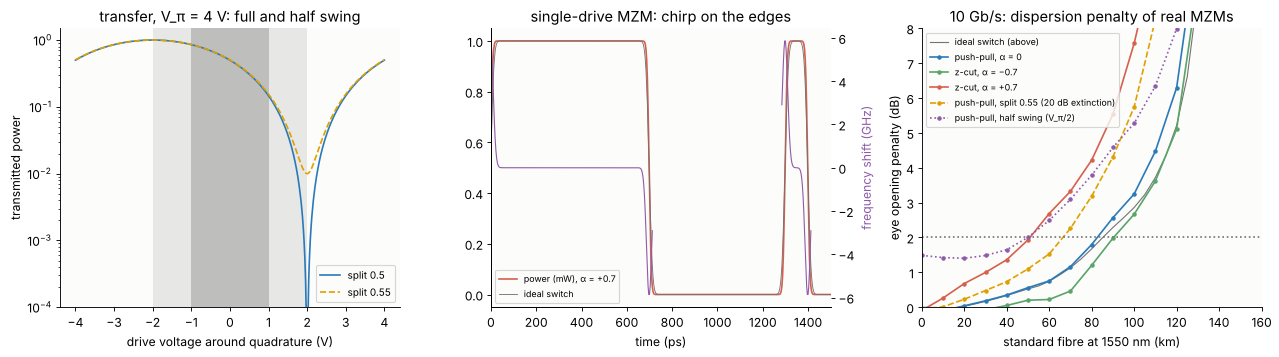

push-pull, α = 0                           back to back -0.1 dB, 2 dB reach 83 km
z-cut, α = −0.7                            back to back -0.1 dB, 2 dB reach 90 km
z-cut, α = +0.7                            back to back -0.1 dB, 2 dB reach 51 km
push-pull, split 0.55 (20 dB extinction)   back to back -0.1 dB, 2 dB reach 66 km
push-pull, half swing (V_π/2)              back to back +1.5 dB, 2 dB reach 50 km
single drive: chirp peaks +5.9 / -5.9 GHz


In [9]:
V_pi = 4.0
Ls_m = np.arange(0, 161, 10)
mzms = [("push-pull, α = 0", dict(alpha=0.0), BLUE, "-"),
        ("z-cut, α = −0.7", dict(alpha=-0.7), GREEN, "-"),
        ("z-cut, α = +0.7", dict(alpha=0.7), RED, "-"),
        ("push-pull, split 0.55 (20 dB extinction)", dict(alpha=0.0, split=0.55), ORANGE, "--"),
        ("push-pull, half swing (V_π/2)", dict(alpha=0.0, swing=V_pi/2), PURPLE, ":")]
pen_mzm = {}
for name, kw, c, ls in mzms:
    _, A = eo.mzm_nrz(bits2, B, V_pi=V_pi, samples_per_bit=32, p_in=1.0, **kw)
    ops = [eye(A, L, beta2)[2] for L in Ls_m]
    pen_mzm[name] = 10*np.log10(open0["external modulator, 1550 nm"]/np.maximum(ops, 1e-12))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
V = np.linspace(-V_pi, V_pi, 401)
ax = axes[0]
ax.plot(V, eo.mzm_power(V, V_pi, bias=np.pi/2), color=BLUE, label="split 0.5")
ax.plot(V, eo.mzm_power(V, V_pi, bias=np.pi/2, split=0.55), color=ORANGE, ls="--", label="split 0.55")
for v, a in ((V_pi/2, 0.15), (V_pi/4, 0.35)):
    ax.axvspan(-v, v, color=GREY, alpha=a, lw=0)
ax.set_yscale("log"); ax.set_ylim(1e-4, 1.5)
ax.set_xlabel("drive voltage around quadrature (V)"); ax.set_ylabel("transmitted power")
ax.set_title("transfer, V_π = 4 V: full and half swing")
ax.legend(fontsize=9, loc="lower right")

ax = axes[1]
_, A_q = eo.mzm_nrz(bits2, B, V_pi=V_pi, samples_per_bit=32, p_in=1.0, alpha=0.7)
P_q = np.abs(A_q)**2
nu_q = -np.gradient(np.unwrap(np.angle(A_q)), t2[1] - t2[0])/(2*np.pi)*1E3
ax.plot(t2, P_q, color=RED, label="power (mW), α = +0.7")
ax.plot(t2, np.abs(A_em2)**2, color=GREY, lw=0.8, label="ideal switch")
ax2 = ax.twinx()
ax2.plot(t2, np.where(P_q > 0.02, nu_q, np.nan), color=PURPLE, lw=1)
ax2.set_ylabel("frequency shift (GHz)", color=PURPLE)
ax.set_xlim(0, 15*T_bit); ax.set_xlabel("time (ps)"); ax.legend(fontsize=8, loc="lower left")
ax.set_title("single-drive MZM: chirp on the edges")

ax = axes[2]
ax.plot(Ls, pen_em, color=GREY, lw=1, label="ideal switch (above)")
for name, kw, c, ls in mzms:
    ax.plot(Ls_m, pen_mzm[name], ls, color=c, marker="o", ms=3, label=name)
ax.axhline(2, color=GREY, ls=":")
ax.set_ylim(0, 8); ax.set_xlim(0, 160)
ax.set_xlabel("standard fibre at 1550 nm (km)"); ax.set_ylabel("eye opening penalty (dB)")
ax.set_title("10 Gb/s: dispersion penalty of real MZMs")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

for name, *_ in mzms:
    p = pen_mzm[name]
    r = "{:.0f} km".format(reach(Ls_m, p)) if np.any(p > 2) else "beyond 160 km"
    print("{:42s} back to back {:+.1f} dB, 2 dB reach {}".format(name, p[0], r))
print("single drive: chirp peaks {:+.1f} / {:+.1f} GHz".format(np.nanmax(np.where(P_q > 0.02, nu_q, np.nan)),
                                                              np.nanmin(np.where(P_q > 0.02, nu_q, np.nan))))


A push-pull modulator driven from null to peak behaves almost like the
ideal switch: 83 km against 85 km at a 2 dB penalty, because the
cosine-squared transfer is slightly sharper than the Gaussian drive edges.
Chirp matters much more. A single-drive modulator biased so that its
rising edges shift to the red ($\alpha = -0.7$, ±6 GHz on the edges)
precompensates the anomalous dispersion of standard fibre and reaches
90 km; biased on the other slope ($\alpha = +0.7$) its blue rising edges
run ahead like those of a directly modulated laser and the reach drops to
51 km, still more than three times that of the DFB laser. A poor
extinction (Y-junctions splitting 55:45, 20 dB) costs a quarter of the
reach: the light left in the zeros interferes with the dispersed tails of
the ones. Driving with half the swing to save driver power gives an eye
that is 1.5 dB smaller from the start, because the transfer is used only
between 15 and 85 %, and 50 km of reach. Commercial 10 Gb/s modulators are
therefore push-pull or chirp-negative devices with an extinction above
25 dB and a driver swing close to $V_\pi$.

## 6. Link budgets

The design of a point-to-point link checks two budgets:

- **power budget:** launch power minus fibre loss, splices (about 0.1 dB
  each, one every 2 to 4 km of cable), connectors (0.3 to 0.5 dB) and
  penalties (dispersion, extinction ratio) must leave the received power a
  margin of 3 dB or more above the sensitivity,
- **rise-time budget:** the rise times of transmitter, fibre (from the
  dispersion, $\Delta\tau = |D|L\sigma_\lambda$ for a broad source, or
  modal dispersion) and receiver ($0.35/\Delta f$) add in quadrature and
  must stay below about 70 % of the bit period for NRZ.

Two examples: a 10 Gb/s link at 1550 nm over 70 km with an APD and an
external modulator (a long reach "ZR"-like link), and a 1 Gb/s link at
1310 nm over 20 km with a Fabry–Perot laser (spectral width 2 nm rms)
and a PIN receiver.

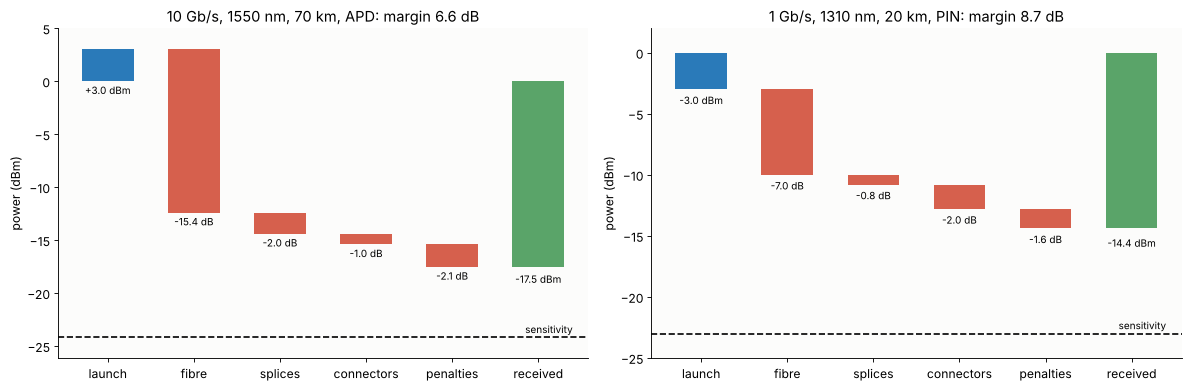

10 Gb/s 1550 nm: launch_dbm 3.0, fibre_db 15.4, splices_db 2.0, connectors_db 1.0, penalties_db 2.1, received_dbm -17.5, sensitivity_dbm -24.2, margin_db 6.6
1 Gb/s 1310 nm: launch_dbm -3.0, fibre_db 7.0, splices_db 0.8, connectors_db 2.0, penalties_db 1.6, received_dbm -14.4, sensitivity_dbm -23.0, margin_db 8.7
rise time, 10 Gb/s link: 58 ps of 70 ps allowed (dispersion in the power budget)
rise time, 1 Gb/s link: transmitter 150, fibre 288, receiver 500 -> 596 ps of 700 ps allowed


In [10]:
P_apd_dbm = fc.dbm(fc.optimum_apd_gain(6, nbw, R, k_A)[1])
pen_70 = float(np.interp(70, Ls, pen_em))
budget_a = fc.power_budget(launch_dbm=3.0, sensitivity_dbm=P_apd_dbm, length_km=70,
                           loss_db_km=0.22, splices=20, splice_db=0.1, connectors=2,
                           connector_db=0.5, penalties_db=pen_70 + 1.0)
B_b, f3_b = 1.0, 0.7
nbw_b = fc.noise_bandwidth(f3_b)
P_pin_b = fc.dbm(fc.sensitivity(6, nbw_b, 0.85))
pen_b = float(fc.dispersion_penalty(B_b, 20, D1310 + 0.09*25, 2.0))   # FP laser 25 nm off the zero
budget_b = fc.power_budget(launch_dbm=-3.0, sensitivity_dbm=P_pin_b, length_km=20, loss_db_km=0.35,
                           splices=8, splice_db=0.1, connectors=4, connector_db=0.5,
                           penalties_db=pen_b + 1.0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, bud, title in ((axes[0], budget_a, "10 Gb/s, 1550 nm, 70 km, APD"),
                       (axes[1], budget_b, "1 Gb/s, 1310 nm, 20 km, PIN")):
    steps = [("launch", bud["launch_dbm"]), ("fibre", -bud["fibre_db"]),
             ("splices", -bud["splices_db"]), ("connectors", -bud["connectors_db"]),
             ("penalties", -bud["penalties_db"])]
    level = 0.0
    for i, (name, val) in enumerate(steps):
        bottom = 0 if i == 0 else level
        ax.bar(i, val, bottom=bottom, color=BLUE if i == 0 else RED, width=0.6)
        level = val if i == 0 else level + val
        ax.text(i, min(bottom, bottom + val) - 1.2, f"{val:+.1f} dB" if i else f"{val:+.1f} dBm",
                ha="center", fontsize=9)
    ax.set_ylim(bud["sensitivity_dbm"] - 2, max(bud["launch_dbm"], 0) + 2)
    ax.bar(len(steps), level, color=GREEN, width=0.6)
    ax.text(len(steps), level - 1.5, f"{level:.1f} dBm", ha="center", fontsize=9)
    ax.axhline(bud["sensitivity_dbm"], color="k", ls="--")
    ax.text(len(steps) + 0.4, bud["sensitivity_dbm"] + 0.4, "sensitivity", ha="right", fontsize=9)
    ax.set_xticks(range(len(steps) + 1), [s for s, _ in steps] + ["received"])
    ax.set_ylabel("power (dBm)")
    ax.set_title(f"{title}: margin {bud['margin_db']:.1f} dB")
plt.tight_layout()
plt.show()

for name, bud in (("10 Gb/s 1550 nm", budget_a), ("1 Gb/s 1310 nm", budget_b)):
    print("{}: ".format(name) + ", ".join("{} {:.1f}".format(k, v) for k, v in bud.items()))

# rise-time budgets (ps)
tr_a = fc.rise_time_budget(0.3*T_bit, 0.0, 350/f3)
tr_fibre_b = abs(D1310 + 0.09*25)*20*2.0*2.355     # FWHM-like spread of a 2 nm rms source
tr_b = fc.rise_time_budget(150.0, tr_fibre_b, 350/f3_b)
print("rise time, 10 Gb/s link: {:.0f} ps of {:.0f} ps allowed (dispersion in the power budget)".format(
    tr_a, 0.7*T_bit))
print("rise time, 1 Gb/s link: transmitter 150, fibre {:.0f}, receiver {:.0f} -> {:.0f} ps of {:.0f} ps allowed".format(
    tr_fibre_b, 350/f3_b, tr_b, 0.7*1E3/B_b))

The long 10 Gb/s link closes with 6.6 dB to spare: 70 km of cabled fibre
cost 15 dB, the dispersion of 1200 ps/nm about 1 dB (plus 1 dB for the
extinction ratio and ageing), and an APD is needed: a PIN receiver would
leave less than 1 dB of margin. The short 1 Gb/s link has
plenty of power; with a Fabry–Perot laser 25 nm off the dispersion zero its
dispersion is still small at this bit rate. The rise-time budget is the
quick check for broad sources and multimode fibres; for a narrow laser at
10 Gb/s and above the dispersion is better counted as a power penalty, as
in section 5.

## 7. Beyond a single span

Real networks go further with three ideas, which are beyond this series:

- **Optical amplifiers.** An erbium-doped fibre amplifier (EDFA) pumped
  at 980 or 1480 nm amplifies the whole C band by 20 to 30 dB. Spans of
  80 to 100 km are chained with an amplifier after each, and the loss
  limit disappears; amplified spontaneous emission becomes the noise, and
  the optical signal to noise ratio (OSNR) replaces the thermal noise.
- **Wavelength division multiplexing.** Many channels on the ITU grid
  (100 or 50 GHz spacing, notebook 119, fibre Bragg gratings) share one fibre and one
  amplifier; 80 channels at 10 Gb/s carry 0.8 Tb/s. Gratings and thin film
  filters (notebooks 12 (layer stacks) to 14 (coated laser mirror)) add and drop them.
- **Coherent receivers.** Mixing the signal with a local oscillator laser
  recovers amplitude and phase; modulation formats such as QPSK and 16-QAM
  carry several bits per symbol, and digital signal processing undoes
  chromatic dispersion and PMD (notebook 117, dispersion in fibres) in software. Modern links
  carry 400 Gb/s to 1.6 Tb/s per wavelength this way.

At high powers in long amplified links, the Kerr effect of silica (self
and cross phase modulation, four wave mixing) also starts to matter; that
nonlinear regime is left out here.

## Summary

- **Loss:** 0.18 dB/km at 1550 nm (Rayleigh scattering meets infrared
  absorption), 0.31 dB/km at 1310 nm, 1.7 dB/km at 850 nm; powers and
  losses add in dBm and dB.
- **Transmitter:** NRZ on-off keying, extinction ratio, rise time; a
  directly modulated DFB laser, from its rate equations, overshoots,
  chirps from −15 to +41 GHz and has its ones 6 GHz bluer than its
  zeros; its intensity noise (RIN −125 to −142 dB/Hz) caps Q near 50,
  harmless at 10 Gb/s.
- **Receiver:** BER = erfc(Q/√2)/2, Q = 6 for 1e-9. At 10 Gb/s a PIN
  receiver needs about −18 dBm (thermal noise limited), an APD at its
  optimum gain about −24 dBm (3000 photons per bit), both far above the
  quantum limit of 10 photons per bit.
- **Simulation:** the Q measured from noisy samples follows the formula,
  about 0.2 dB lower because of the intersymbol interference of the
  receiver filter.
- **Dispersion:** 10 Gb/s with an external modulator reaches about 85 km of
  standard fibre at 1550 nm (2 dB penalty, about 1500 ps/nm); a directly
  modulated DFB laser only 15 km (a transient chirp model alone: 8 km). A real Mach–Zehnder modulator reaches
  90 km with negative chirp, 51 km with positive chirp and 66 km with
  20 dB extinction. At 1310 nm, loss limits instead.
- **Budgets:** power budget with 3 dB margin, rise times in quadrature
  below 70 % of a bit.

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 9 s


## References

- G. P. Agrawal, *Fiber-Optic Communication Systems*, 4th ed., Wiley
  (2010), chapters 2 to 5.
- G. Keiser, *Optical Fiber Communications*, 5th ed., McGraw-Hill (2015).
- J. M. Senior, *Optical Fiber Communications: Principles and Practice*,
  3rd ed., Pearson (2009).
- R. J. McIntyre, "Multiplication noise in uniform avalanche diodes", IEEE
  Trans. Electron Devices 13, 164–168 (1966).
- T. L. Koch and R. A. Linke, "Effect of nonlinear gain reduction on
  semiconductor laser wavelength chirping", Appl. Phys. Lett. 48, 613–615
  (1986).
- ITU-T G.652 (standard single-mode fibre), G.957 and G.959.1 (optical
  interfaces), G.694.1 (DWDM grid).